# Watermark 입장 상한의 비용: 보조 민감도 분석

이 노트북은 **미리 정한 GPU 여유 제약을 적용할 때 추가되는 비용**을 기록한다. 상한을 낮추면 회수가 빨라진다는 방향은 구현으로 예상할 수 있으며, 이를 새로운 정책 효과의 발견으로 제시하지 않는다.

| 확인한 것 | 이 실험으로 확인하지 않은 것 |
|---|---|
| 같은 입력에서 전송·입장 대기·normal 지연·복귀 지연의 변화 | GPU 공간을 10% 남겨야 하는 운영상의 이유 |
| 각 상한을 지키는 구현 불변식 | 확보한 여유 공간을 실제로 활용했을 때의 서비스 이득 |
| 기존 SLO의 구성 요소와 상대 기준의 영향 | 최적 상한이나 Watermark의 사용자 성능 우위 |

실행 범위는 상한 **80·85·90·95·100%**와 LRU, 세 설정(60초·0.2/s, 180초·0.2/s, 180초·0.3/s), 기존 9조건, seed 0~14다. 2026-11-03에 스크립트로 실행한 2,430회 결과를 읽으며, 실행 횟수 자체를 연구 기여로 해석하지 않는다.

[사전 계획](../docs/week10_watermark_ceiling_plan.md) · [비용 분석 보고서](../docs/week10_watermark_ceiling.md). 이 해석 범위 정리는 실행 후 작성했다. 사전 가설·SLO·원자료는 소급 변경하지 않았다.

## 1. 환경과 재현 옵션

기본값은 **저장된 결과 읽기**다. 원자료는 Git 추적 대상이 아니다. 다른 환경에서 실행할 때 원자료를 복사하거나, `RUN_EXPERIMENT=True`로 바꾸고 새 출력 경로를 지정한다. 전체 실험 재현에는 2,430회 시뮬레이션이 필요하다.

In [1]:
import json, math, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'kvbench').is_dir() and (p / 'configs').is_dir())
for directory in (ROOT, ROOT / 'scripts'):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
from run_watermark_ceiling import run_ceiling_sweep, sha256
from report_watermark_ceiling import clustered_delta_ci

get_ipython().run_line_magic('matplotlib', 'inline')
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

RUN_EXPERIMENT = False
SAVED_OUTPUT = ROOT / 'results/week10_watermark_ceiling_20261103'
NEW_OUTPUT = ROOT / 'results/week10_watermark_ceiling_notebook_replay'

if RUN_EXPERIMENT:
    if NEW_OUTPUT.exists():
        raise FileExistsError('기존 출력과 겹칩니다. NEW_OUTPUT을 새 경로로 지정하세요.')
    run_ceiling_sweep(NEW_OUTPUT, progress=lambda s: print(s, flush=True))
    OUTPUT = NEW_OUTPUT
else:
    OUTPUT = SAVED_OUTPUT
if not (OUTPUT / 'experiment.json').exists():
    raise FileNotFoundError('원자료가 없습니다. SAVED_OUTPUT을 확인하거나 RUN_EXPERIMENT=True로 재현하세요.')
manifest = json.loads((OUTPUT / 'experiment.json').read_text(encoding='utf-8'))
assert manifest['status'] == 'complete'
print('ROOT:', ROOT)
print('OUTPUT:', OUTPUT)
print('실험 상태:', manifest['status'], '| 실행 수:', manifest['actual_runs'])

ROOT: C:\Users\user\Desktop\kv-bench
OUTPUT: C:\Users\user\Desktop\kv-bench\results\week10_watermark_ceiling_20261103
실험 상태: complete | 실행 수: 2430


## 2. 실제 입력과 결과 완전성 확인

In [2]:
raw = pd.read_csv(OUTPUT / 'ceiling_runs.csv')
slo = pd.read_csv(OUTPUT / 'ceiling_slo_by_seed.csv')
slo['passed'] = slo['all_pass'].astype(str).str.lower().eq('true')
VARIANTS = ['lru_offload', 'watermark_c0.8', 'watermark_c0.85', 'watermark_c0.9', 'watermark_c0.95', 'watermark_c1']
SETTINGS = list(manifest['settings'])
LOADS = [item[0] for item in manifest['conditions']]
LABEL = {'lru_offload': 'LRU (100%)', **{f'watermark_c{c:g}': f'{c * 100:g}%' for c in manifest['ceilings']}}

assert len(raw) == len(slo) == manifest['expected_runs'] == 2430
assert not raw.duplicated(['setting', 'variant', 'load', 'seed']).any()
assert raw.groupby(['setting', 'variant']).size().eq(135).all()
assert raw['ceiling_violations'].eq(0).all()
assert (raw.used_blocks_max <= raw.admission_limit_blocks).all()
changed_sources = [name for name, digest in manifest['source_sha256'].items()
                   if not (ROOT / name).exists() or sha256(ROOT / name) != digest]
print('현재 코드와 실험 당시 코드의 차이:', changed_sources or '없음')
display(raw.groupby(['setting', 'variant']).size().unstack().loc[SETTINGS, VARIANTS])
print('상한:', manifest['ceilings'], '| seed:', manifest['seeds'])

현재 코드와 실험 당시 코드의 차이: 없음


variant,lru_offload,watermark_c0.8,watermark_c0.85,watermark_c0.9,watermark_c0.95,watermark_c1
setting,,,,,,
60s_02,135,135,135,135,135,135
180s_02,135,135,135,135,135,135
180s_03,135,135,135,135,135,135


상한: [0.8, 0.85, 0.9, 0.95, 1.0] | seed: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]


## 3. LRU 대비 비용과 전체 지표

먼저 주 설정인 180초·0.2/s에서 LRU와 90%의 **서비스 지표와 비용**을 비교한다. Peak 제약 충족과 사용자 성능을 구분한다. 각 run의 P95를 계산한 뒤 9조건 × 15 seed를 평균하며 전체 요청을 합친 P95는 아니다. 개별 조건·seed에서는 평균과 다른 변화가 생길 수 있다.

그 뒤 세 설정의 비용을 나란히 본다. normal 거절률은 최대, stress 완료율은 세션 수로 계산한다. 서로 다른 기간의 전송량을 효율 순위로 비교하지 않는다. 기존 SLO 통과 수와 할당 상한은 보조 집계인 6절로 분리한다.

In [3]:
def summarize(frame):
    frame = frame.copy()
    frame['transfer_gib'] = frame.transfer_bytes / 2**30
    result = frame.groupby(['setting', 'variant']).agg(
        runs=('run_id', 'size'),
        normal_p95_ms=('normal_p95_ttft_ms', 'mean'),
        normal_admission_p95_ms=('normal_p95_admission_wait_ms', 'mean'),
        peak_mean_pct=('peak_kv_occupancy_pct', 'mean'),
        peak_max_pct=('peak_kv_occupancy_pct', 'max'),
        above90_pct=('kv_above_90_pct_of_time', 'mean'),
        transfer_gib=('transfer_gib', 'mean'),
        resume_p95_ms=('stress_p95_resume_ms', 'mean'),
        reject_max_pct=('normal_reject_rate_pct', 'max'),
        recomputed_tokens=('recomputed_tokens', 'sum'),
        stress_submitted=('stress_submitted_jobs', 'sum'),
        stress_completed=('stress_completed_jobs', 'sum'),
    )
    pass_counts = slo.groupby(['setting', 'variant']).passed.sum()
    if frame.load.nunique() == 1:
        pass_counts = slo[slo.load.eq(frame.load.iloc[0])].groupby(['setting', 'variant']).passed.sum()
    result['slo_pass'] = pass_counts
    result['stress_completion_pct'] = result.stress_completed / result.stress_submitted * 100
    return result

summary = summarize(raw)
columns = ['normal_p95_ms', 'normal_admission_p95_ms', 'transfer_gib', 'resume_p95_ms',
           'reject_max_pct', 'stress_completion_pct']
main = summary.loc['180s_02']
lru, wm90 = main.loc['lru_offload'], main.loc['watermark_c0.9']
comparison = pd.DataFrame({
    'LRU': [lru.normal_p95_ms, lru.transfer_gib, lru.resume_p95_ms, lru.reject_max_pct, lru.stress_completion_pct],
    'Watermark 90%': [wm90.normal_p95_ms, wm90.transfer_gib, wm90.resume_p95_ms, wm90.reject_max_pct, wm90.stress_completion_pct],
}, index=['normal P95 (ms)', '전송 (GiB/run)', '복귀 P95 (ms)', 'normal 거절률 최대 (%)', 'stress 완료율 (%)'])
comparison['90% - LRU'] = comparison['Watermark 90%'] - comparison['LRU']
print('주 설정: LRU 대비 비용')
display(comparison)
print('이 집계에서 지연은 길고 전송은 많았으며, 거절·완료율의 이득은 관찰되지 않았다.')
print('Peak 제약을 지킨 사실로 사용자 성능 향상이나 여유 공간의 필요성을 입증하지 않는다.')
for setting in SETTINGS:
    print(setting, '| 각 행 135 run의 비용 지표')
    table = summary.loc[setting].loc[VARIANTS, columns].copy()
    table.index = [LABEL[v] for v in table.index]
    display(table)
assert summary.reject_max_pct.eq(0).all()
assert summary.recomputed_tokens.eq(0).all()
assert summary.stress_completion_pct.eq(100).all()
print('전체 실행: normal 거절 0, 재계산 0. stress는 drain을 포함해 100% 완료.')

주 설정: LRU 대비 비용


,LRU,Watermark 90%,90% - LRU
normal P95 (ms),270.06,271.79,1.74
전송 (GiB/run),17.92,23.36,5.44
복귀 P95 (ms),199.48,213.43,13.94
normal 거절률 최대 (%),0.00,0.00,0.00
stress 완료율 (%),100.00,100.00,0.00


이 집계에서 지연은 길고 전송은 많았으며, 거절·완료율의 이득은 관찰되지 않았다.
Peak 제약을 지킨 사실로 사용자 성능 향상이나 여유 공간의 필요성을 입증하지 않는다.
60s_02 | 각 행 135 run의 비용 지표


,normal_p95_ms,normal_admission_p95_ms,transfer_gib,resume_p95_ms,reject_max_pct,stress_completion_pct
LRU (100%),308.06,0.50,2.87,132.73,0.00,100.00
80%,320.27,12.94,6.31,155.52,0.00,100.00
85%,310.74,4.37,5.20,144.31,0.00,100.00
90%,308.98,0.51,4.33,141.42,0.00,100.00
95%,308.60,0.75,3.50,133.93,0.00,100.00
100%,308.06,0.50,2.87,132.73,0.00,100.00


180s_02 | 각 행 135 run의 비용 지표


,normal_p95_ms,normal_admission_p95_ms,transfer_gib,resume_p95_ms,reject_max_pct,stress_completion_pct
LRU (100%),270.06,0.00,17.92,199.48,0.00,100.00
80%,283.07,1.20,30.67,236.12,0.00,100.00
85%,274.80,0.51,26.82,216.41,0.00,100.00
90%,271.79,0.03,23.36,213.43,0.00,100.00
95%,271.25,0.00,20.49,201.94,0.00,100.00
100%,270.06,0.00,17.92,199.48,0.00,100.00


180s_03 | 각 행 135 run의 비용 지표


,normal_p95_ms,normal_admission_p95_ms,transfer_gib,resume_p95_ms,reject_max_pct,stress_completion_pct
LRU (100%),447.52,1.56,45.29,334.54,0.00,100.00
80%,511.05,70.14,65.12,478.57,0.00,100.00
85%,481.80,27.04,60.03,407.08,0.00,100.00
90%,464.11,9.72,54.88,372.32,0.00,100.00
95%,454.48,4.10,49.83,340.88,0.00,100.00
100%,447.52,1.56,45.29,334.54,0.00,100.00


전체 실행: normal 거절 0, 재계산 0. stress는 drain을 포함해 100% 완료.


## 4. 관측한 비용 곡선

normal 지연·전송·복귀 지연·입장 대기의 변화를 보여준다. 상한을 따르는 Peak 곡선은 구조적 성질이므로 주요 성능 그래프로 쓰지 않는다. 모든 패널은 135개 run 지표의 평균이며, 상한 변경이 모든 요청에 같은 영향을 준다는 뜻은 아니다. 100% Watermark는 검증상 LRU와 같은 동작이다.

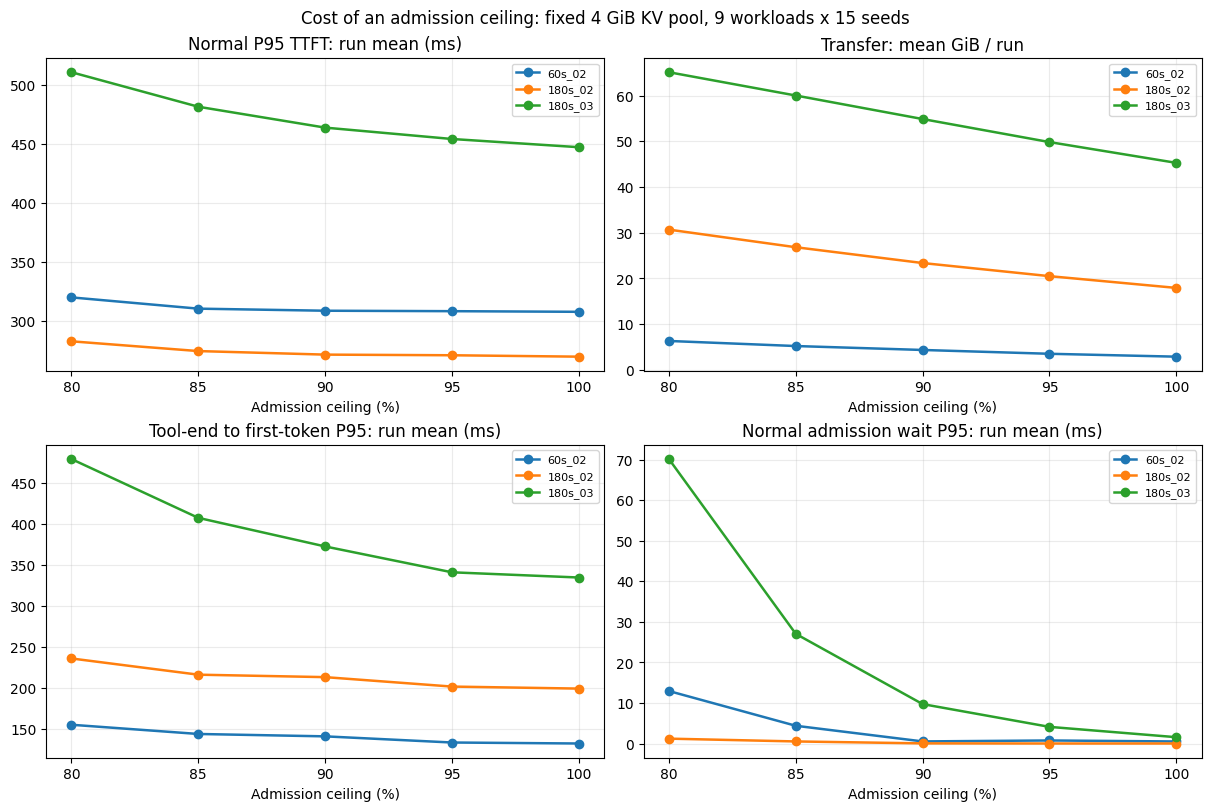

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
metrics = [('normal_p95_ms', 'Normal P95 TTFT: run mean (ms)'),
           ('transfer_gib', 'Transfer: mean GiB / run'),
           ('resume_p95_ms', 'Tool-end to first-token P95: run mean (ms)'),
           ('normal_admission_p95_ms', 'Normal admission wait P95: run mean (ms)')]
watermark_variants = VARIANTS[1:]
x = [c * 100 for c in manifest['ceilings']]
for ax, (metric, title) in zip(axes.flat, metrics):
    for setting in SETTINGS:
        y = summary.loc[setting].loc[watermark_variants, metric]
        ax.plot(x, y, marker='o', linewidth=1.8, label=setting)
    ax.set(title=title, xlabel='Admission ceiling (%)', xticks=x)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle('Cost of an admission ceiling: fixed 4 GiB KV pool, 9 workloads x 15 seeds')
display(fig)
plt.close(fig)

## 5. 대표 조건 both_4x

각 행은 같은 조건의 seed 15개 평균이다. 전체 9조건 평균과 구분한다. 완료율 100%는 입력 종료 이후 drain에서 완료한 세션도 포함한다.

In [5]:
representative = summarize(raw[raw.load.eq('both_4x')])
for setting in SETTINGS:
    print(setting, '| 각 행 15 runs')
    table = representative.loc[setting].loc[VARIANTS, columns].copy()
    table.index = [LABEL[v] for v in table.index]
    display(table)

60s_02 | 각 행 15 runs


,normal_p95_ms,normal_admission_p95_ms,transfer_gib,resume_p95_ms,reject_max_pct,stress_completion_pct
LRU (100%),404.86,0.26,3.58,64.48,0.00,100.00
80%,410.47,0.00,6.12,71.30,0.00,100.00
85%,406.07,0.00,5.49,70.48,0.00,100.00
90%,404.17,0.00,5.10,68.46,0.00,100.00
95%,403.28,0.00,4.31,71.65,0.00,100.00
100%,404.86,0.26,3.58,64.48,0.00,100.00


180s_02 | 각 행 15 runs


,normal_p95_ms,normal_admission_p95_ms,transfer_gib,resume_p95_ms,reject_max_pct,stress_completion_pct
LRU (100%),324.69,0.00,25.44,151.10,0.00,100.00
80%,333.83,0.00,31.87,171.37,0.00,100.00
85%,332.18,0.00,30.65,163.95,0.00,100.00
90%,327.18,0.00,28.40,155.39,0.00,100.00
95%,326.97,0.00,26.88,149.19,0.00,100.00
100%,324.69,0.00,25.44,151.10,0.00,100.00


180s_03 | 각 행 15 runs


,normal_p95_ms,normal_admission_p95_ms,transfer_gib,resume_p95_ms,reject_max_pct,stress_completion_pct
LRU (100%),626.51,2.27,48.47,238.15,0.00,100.00
80%,649.15,68.28,60.78,297.33,0.00,100.00
85%,646.54,19.22,57.33,264.11,0.00,100.00
90%,627.47,4.97,53.49,248.65,0.00,100.00
95%,624.64,3.11,50.69,225.18,0.00,100.00
100%,626.51,2.27,48.47,238.15,0.00,100.00


## 6. 보조 집계: 기존 SLO의 구성 요소와 할당 제약

기존 판정은 Peak ≤ 90%, normal 거절률 ≤ 10%, 각 변형·같은 seed의 W0 P95 대비 3배 이하다. 80~90%는 Peak 기준을 구조적으로 만족하고, 95~100%는 더 큰 할당량을 허용한다. 따라서 전체 통과 수를 서비스 품질 순위로 사용하지 않는다.

먼저 주 설정 135회의 **상대 TTFT·거절률·Peak·전체 통과 수를 분리**한다. 이어지는 조건별 표의 분모는 seed 15개다. 상한 준수는 구현 검증이고, 90% 여유의 운영 필요성이나 성능 효과의 검증은 아니다.

In [6]:
primary_slo = slo[slo.setting.eq('180s_02')]
parts = primary_slo[['variant']].copy()
for field in ['ttft_pass', 'reject_pass', 'occupancy_pass', 'all_pass']:
    parts[field] = primary_slo[field].astype(str).str.lower().eq('true')
parts = parts.groupby('variant').sum().loc[VARIANTS].astype(int)
parts.columns = ['상대 TTFT 통과 /135', '거절률 통과 /135', 'Peak 통과 /135', '전체 통과 /135']
parts['관측 최대 Peak (%)'] = summary.loc['180s_02'].loc[VARIANTS, 'peak_max_pct']
parts.index = [LABEL[v] for v in parts.index]
display(parts)
print('조건별 전체 통과 수 /15 (서비스 성능 순위가 아님)')
pass_table = primary_slo.pivot_table(index='variant', columns='load', values='passed', aggfunc='sum')
pass_table = pass_table.loc[VARIANTS, LOADS].astype(int)
pass_table.index = [LABEL[v] for v in pass_table.index]
display(pass_table)
remaining = slo[(slo.admission_ceiling <= 0.9) & ~slo.passed]
assert remaining.ttft_pass.astype(str).str.lower().eq('false').all()
assert remaining.reject_pass.astype(str).str.lower().eq('true').all()
assert remaining.occupancy_pass.astype(str).str.lower().eq('true').all()
print('80~90%에서 남은 실패:', len(remaining), '회. 모두 상대 TTFT 기준만 실패.')

,상대 TTFT 통과 /135,거절률 통과 /135,Peak 통과 /135,전체 통과 /135,관측 최대 Peak (%)
LRU (100%),134,135,5,5,100.00
80%,134,135,135,134,80.00
85%,134,135,135,134,85.00
90%,134,135,135,134,90.00
95%,134,135,5,5,95.00
100%,134,135,5,5,100.00


조건별 전체 통과 수 /15 (서비스 성능 순위가 아님)


load,w0_1x,base_2x,burst_2x,wait_2x,both_2x,base_4x,burst_4x,wait_4x,both_4x
LRU (100%),5,0,0,0,0,0,0,0,0
80%,15,15,15,15,15,15,15,15,14
85%,15,15,15,15,15,15,15,15,14
90%,15,15,15,15,15,15,15,15,14
95%,5,0,0,0,0,0,0,0,0
100%,5,0,0,0,0,0,0,0,0


80~90%에서 남은 실패: 66 회. 모두 상대 TTFT 기준만 실패.


## 7. 90% 대비 같은 입력의 변화

동일 조건·seed끼리 차이를 계산한다. 각 seed에서 9조건 평균 차이를 구하고 seed 15개를 2,000회 bootstrap 재표집한 95% 구간을 보조적으로 표시한다. 135개 실행을 독립 seed로 취급하거나 유의성 검정·최적값 선택에 사용하지 않는다.

In [7]:
paired = []
primary_records = raw[raw.setting.eq('180s_02')].to_dict('records')
reference = {(r['load'], r['seed']): r for r in primary_records if r['variant'] == 'watermark_c0.9'}
for variant in VARIANTS:
    selected = [r for r in primary_records if r['variant'] == variant]
    delta, low, high = clustered_delta_ci(selected, reference, 'normal_p95_ttft_ms')
    differences = [r['normal_p95_ttft_ms'] - reference[r['load'], r['seed']]['normal_p95_ttft_ms'] for r in selected]
    paired.append({'variant': LABEL[variant], 'delta_ms': delta, 'bootstrap_low_ms': low, 'bootstrap_high_ms': high,
                   'increased': sum(d > 1e-7 for d in differences),
                   'decreased': sum(d < -1e-7 for d in differences),
                   'same': sum(abs(d) <= 1e-7 for d in differences)})
display(pd.DataFrame(paired).set_index('variant'))

baseline90 = summary.loc[('180s_02', 'watermark_c0.9')]
cap80 = summary.loc[('180s_02', 'watermark_c0.8')]
print(f"90% → 80%: normal P95 {cap80.normal_p95_ms - baseline90.normal_p95_ms:+.2f} ms")
print(f"전송 {100 * (cap80.transfer_gib / baseline90.transfer_gib - 1):+.2f}%")
print(f"복귀 P95 {cap80.resume_p95_ms - baseline90.resume_p95_ms:+.2f} ms")

,delta_ms,bootstrap_low_ms,bootstrap_high_ms,increased,decreased,same
variant,,,,,,
LRU (100%),-1.74,-3.10,-0.33,14,36,85
80%,11.27,5.53,17.38,48,20,67
85%,3.00,-0.54,6.96,33,25,77
90%,0.00,0.00,0.00,0,0,135
95%,-0.55,-2.15,0.96,16,24,95
100%,-1.74,-3.10,-0.33,14,36,85


90% → 80%: normal P95 +11.27 ms
전송 +31.30%
복귀 P95 +22.69 ms


## 8. 과부하에서 통과 수와 절대 성능이 다른 사례

180초·0.3/s에서는 85%가 90%보다 SLO를 더 많이 통과해도 평균 절대 지연은 더 길다. 각 변형의 W0 기준이 달라지므로 절대 지연과 상대 비율을 함께 본다.

In [8]:
left = slo[slo.variant.eq('watermark_c0.9')]
right = slo[slo.variant.eq('watermark_c0.85')]
keys = ['setting', 'load', 'seed']
changed = left.merge(right, on=keys, suffixes=('_90', '_85'))
changed = changed[changed.passed_90.ne(changed.passed_85)]
display(changed[keys + ['passed_90', 'passed_85', 'normal_p95_ttft_ms_90', 'normal_p95_ttft_ms_85',
                        'w0_p95_ttft_ms_90', 'w0_p95_ttft_ms_85',
                        'ttft_ratio_vs_policy_w0_90', 'ttft_ratio_vs_policy_w0_85']])
print('통과 여부가 달라진 쌍:', len(changed))

,setting,load,seed,passed_90,passed_85,normal_p95_ttft_ms_90,normal_p95_ttft_ms_85,w0_p95_ttft_ms_90,w0_p95_ttft_ms_85,ttft_ratio_vs_policy_w0_90,ttft_ratio_vs_policy_w0_85
305,180s_03,burst_2x,14,False,True,871.17,888.33,276.87,325.18,3.15,2.73
335,180s_03,both_2x,14,False,True,848.16,823.23,276.87,325.18,3.06,2.53
340,180s_03,both_2x,5,True,False,432.58,457.82,147.52,147.52,2.93,3.10
363,180s_03,burst_4x,12,False,True,"1,075.80","1,059.48",321.02,380.29,3.35,2.79
365,180s_03,burst_4x,14,False,True,871.17,871.17,276.87,325.18,3.15,2.68
395,180s_03,both_4x,14,False,True,848.16,916.63,276.87,325.18,3.06,2.82


통과 여부가 달라진 쌍: 6


## 9. 구현 동작을 확인하는 점유율 사례

기존 10주차 리뷰와 같은 180초·0.2/s, both_4x, seed 1이다. 상한을 따르는 동작을 시각적으로 확인하는 사례로 사용하며, 곡선이 낮아졌다는 사실을 서비스 이득으로 해석하지 않는다. 입력 구간 0~180초만 표시하고 기존 Peak SLO에는 drain도 포함한다.

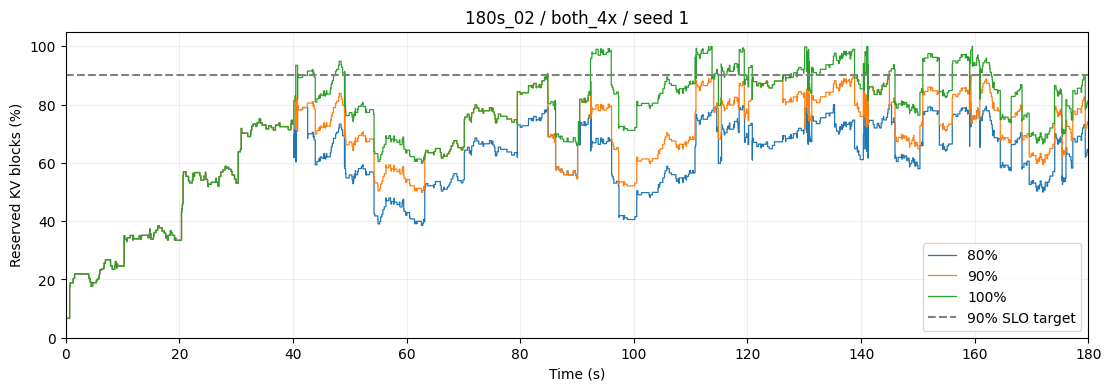

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.8), constrained_layout=True)
for variant in ['watermark_c0.8', 'watermark_c0.9', 'watermark_c1']:
    row = raw[(raw.setting == '180s_02') & (raw.variant == variant) & (raw.load == 'both_4x') & (raw.seed == 1)].iloc[0]
    occupancy = pd.read_csv(OUTPUT / row.relative_run_dir / 'occupancy.csv')
    ax.step(occupancy.time_ms / 1000, occupancy.used_blocks / occupancy.total_blocks * 100,
            where='post', linewidth=0.9, label=LABEL[variant])
ax.axhline(90, color='gray', linestyle='--', label='90% SLO target')
ax.set(xlim=(0, 180), ylim=(0, 105), xlabel='Time (s)', ylabel='Reserved KV blocks (%)',
       title='180s_02 / both_4x / seed 1')
ax.grid(alpha=0.2)
ax.legend()
display(fig)
plt.close(fig)

## 10. 실행 정합성과 상한 불변식 검증

아래 수치는 실행기가 원본 파일을 검사해 저장한 값이다. 이는 재현·구현 검증이며 정책의 사용자 성능 우위를 증명하는 실험은 아니다.

복귀 지연은 실제 TOOL_END부터 다음 턴의 첫 토큰까지다. offload 중 요청 등록이 늦어지는 기존 동작을 바꾸지 않고 잔여 대기를 포함했다. 첫 턴을 제외하고 도구 종료가 warm-up 이후인 완료 stress 복귀 턴에서 P95를 구한다. 완료된 표본의 지연은 거절·완료 수와 함께 해석한다.

In [10]:
checks = {
    '완료 run 수': manifest['actual_runs'],
    '상한 위반': manifest['occupancy_ceiling_violations'],
    'Watermark 100%와 LRU 동일 결과': manifest['watermark_100_lru_exact_matches'],
    '기존 9주차 LRU와 동일 결과': manifest['legacy_lru_exact_matches'],
}
assert checks['완료 run 수'] == 2430 and checks['상한 위반'] == 0
assert checks['Watermark 100%와 LRU 동일 결과'] == 405
assert 0 <= checks['기존 9주차 LRU와 동일 결과'] <= 135
if checks['기존 9주차 LRU와 동일 결과'] < 135:
    print('기존 9주차 원자료가 없는 실행은 과거 결과 대조에서 제외됐습니다.')
display(pd.Series(checks, name='검증 결과').to_frame())
display(summary[['reject_max_pct', 'stress_completion_pct', 'stress_submitted', 'stress_completed']])

# 보고서 생성기가 저장한 집계와 이 노트북에서 다시 계산한 수치를 대조한다.
if (OUTPUT / 'aggregate.csv').exists():
    saved = pd.read_csv(OUTPUT / 'aggregate.csv').set_index(['setting', 'variant'])
    for key in summary.index:
        for metric in ['normal_p95_ms', 'peak_mean_pct', 'peak_max_pct', 'transfer_gib', 'resume_p95_ms']:
            assert math.isclose(summary.loc[key, metric], saved.loc[key, metric], abs_tol=1e-8)
    print('보고서 집계와 노트북 재계산 결과 일치')

,검증 결과
완료 run 수,2430
상한 위반,0
Watermark 100%와 LRU 동일 결과,405
기존 9주차 LRU와 동일 결과,135


reject_max_pct  stress_completion_pct  \
setting variant                                                  
180s_02 lru_offload                0.00                 100.00   
        watermark_c0.8             0.00                 100.00   
        watermark_c0.85            0.00                 100.00   
        watermark_c0.9             0.00                 100.00   
        watermark_c0.95            0.00                 100.00   
        watermark_c1               0.00                 100.00   
180s_03 lru_offload                0.00                 100.00   
        watermark_c0.8             0.00                 100.00   
        watermark_c0.85            0.00                 100.00   
        watermark_c0.9             0.00                 100.00   
        watermark_c0.95            0.00                 100.00   
        watermark_c1               0.00                 100.00   
60s_02  lru_offload                0.00                 100.00   
        watermark_c0.8             0.00                 100.00   
        watermark_c0.85            0.00                 100.00   
        watermark_c0.9             0.00                 100.00   
        watermark_c0.95            0.00                 100.00   
        watermark_c1               0.00                 100.00   

                         stress_submitted  stress_completed  
setting variant                                              
180s_02 lru_offload                  4680              4680  
        watermark_c0.8               4680              4680  
        watermark_c0.85              4680              4680  
        watermark_c0.9               4680              4680  
        watermark_c0.95              4680              4680  
        watermark_c1                 4680              4680  
180s_03 lru_offload                  6642              6642  
        watermark_c0.8               6642              6642  
        watermark_c0.85              6642              6642  
        watermark_c0.9               6642              6642  
        watermark_c0.95              6642              6642  
        watermark_c1                 6642              6642  
60s_02  lru_offload                  1503              1503  
        watermark_c0.8               1503              1503  
        watermark_c0.85              1503              1503  
        watermark_c0.9               1503              1503  
        watermark_c0.95              1503              1503  
        watermark_c1                 1503              1503

보고서 집계와 노트북 재계산 결과 일치


## 11. 이 자료에서 내릴 수 있는 결론

- 주 설정의 전체 평균에서 Watermark 90%는 LRU보다 전송 +30.39%, normal P95 +1.74ms, 복귀 P95 +13.94ms였다. 둘 다 거절 0·stress 완료율 100%로, 해당 집계에서 사용자 성능 이득을 관찰하지 못했다. 개별 조건·seed의 변화는 이 평균과 다를 수 있다.
- 주어진 메모리 여유 제약을 더 강하게 적용할 때의 추가 비용을 기록했다. 90%→80%는 **보장되는 최소 여유**를 10%p 늘리는 조작이다. 실제 평균 미사용량이 모든 실행에서 정확히 10%p 늘었다는 뜻은 아니다.
- Peak 상한 준수는 구현으로 보장된다. SLO 통과 수에 그 기준이 포함되므로, 통과 수만으로 사용자 성능 개선이나 최적 상한을 주장하지 않는다.
- 90%라는 목표의 운영 근거, 여유 공간을 사용하는 실제 부하에서의 이득, 그 이득과 비용의 관계는 이 실험에서 검증하지 않았다.
- 거절·재계산이 없고 stress가 drain까지 모두 완료한 것은 현재 CPU 64GiB·PCIe 12GB/s·단일 FIFO prefill 가정 아래의 결과다. 실제 GPU 성능으로 확대하지 않는다.
- 본 자료는 보조 비용 분석으로 보존한다. 서비스 목적함수와 독립 평가 없이 기본값 유지·변경을 권고하지 않는다. 기존 값 90%를 수정하지 않은 사실은 최적값을 선정했다는 뜻이 아니다.

이 범위 정리는 실행 후 작성했다. 사전 계획·기존 SLO·원자료는 그대로 보존한다. [비용 분석 보고서](../docs/week10_watermark_ceiling.md)에서 조건·수치·재현 방법을 확인할 수 있다.